# Sarcasm Blindspot — Phase I
### AI-West · JKU AI and Visualization

**Model:** [`cardiffnlp/twitter-roberta-base-irony`](https://huggingface.co/cardiffnlp/twitter-roberta-base-irony) — binary irony detection, **not sentiment classification**.  
**Dataset:** [TweetEval irony test set](https://github.com/cardiffnlp/tweeteval) (784 tweets: 311 ironic, 473 non-ironic).  
**Hypothesis:** Removing hashtags and emojis changes the model's predicted irony labels and probabilities.

**One notebook for the entire experiment:** source code, three editable Python visualizations with their outputs, statistical comparisons, selected examples, and our team's interaction log.

There is **no embedded dataset, prediction CSV, or base64 image payload in the source cells**. This notebook reads an existing predictions CSV if available; otherwise it downloads the official test data and performs inference with our specified irony model. Its figures appear as normal saved notebook outputs, so no separate PNGs are needed for submission.


## 1. Results at a glance

The values below come from our completed irony-model experiment (displayed charts and tables are regenerated by the Python cells below).

- Original-test irony-detection accuracy: **73.5%**.
- Hashtag removal changes the prediction for **15.4% of affected ironic** tweets versus **13.1% of affected non-ironic** tweets.
- Group difference: **+2.3 percentage points**; the **95% bootstrap interval includes zero** (about −3.4 to +8.0 percentage points).
- Only **33 ironic** and **55 non-ironic** tweets contained emojis that were actually removed.
- Removing an entire hashtag may delete important words. We also test removing only `#`.


## 2. Setup

The notebook uses an existing `results_irony/predictions.csv` (or `predictions.csv` beside the notebook) **if one is present**. This avoids rerunning the already-completed model experiment.

If no predictions CSV is found, it downloads the original TweetEval irony test split and evaluates the **exact** checkpoint `cardiffnlp/twitter-roberta-base-irony`. Downloading the test set and model requires internet access for the first run and the model may take several minutes on CPU.

To *force* a new model run even when a CSV is present, set `USE_EXISTING_PREDICTIONS = False`.

**For submission:** upload only this `.ipynb`. All Python plots and the AI interaction log are inside it.


In [1]:
from pathlib import Path
import re, json, sys, subprocess, importlib.util
from urllib.request import urlopen
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

USE_EXISTING_PREDICTIONS = True   # False = download TweetEval and rerun inference
BATCH_SIZE = 16
RESULTS_DIR = Path("results_irony")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ID = "cardiffnlp/twitter-roberta-base-irony"
DATASET_ID = "cardiffnlp/tweet_eval"
CONDITIONS = (("no_hashtags", "Remove hashtags"),
              ("no_emojis", "Remove emojis"),
              ("no_both", "Remove both"),
              ("marker_only", "Keep words, remove #"))
GROUPS = ((0, "Non-ironic"), (1, "Ironic"))
HASHTAG_RE = re.compile(r"(?<!\w)#[\w]+", re.UNICODE)


## 3. Load the data (no embedded CSV)

The test set is publicly available through [CardiffNLP's TweetEval repository](https://github.com/cardiffnlp/tweeteval/tree/main/datasets/irony). The notebook can also use a locally available `tweet_eval_irony_test.csv`. The data are used only for inference when saved predictions are unavailable.


In [2]:
def load_tweeteval_irony_test():
    """Use a local test CSV or fetch TweetEval's official 784-tweet test split."""
    for path in (Path("tweet_eval_irony_test.csv"), Path("data/tweet_eval_irony_test.csv")):
        if path.is_file():
            data = pd.read_csv(path)
            if {"tweet_raw", "irony_label"}.issubset(data.columns):
                print("Loaded TweetEval from", path)
                return data

    base = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/irony/"
    try:
        with urlopen(base + "test_text.txt", timeout=60) as response:
            tweets = response.read().decode("utf-8-sig").splitlines()
        with urlopen(base + "test_labels.txt", timeout=60) as response:
            labels = [int(s) for s in response.read().decode("utf-8-sig").splitlines() if s.strip()]
    except Exception as error:
        raise RuntimeError("Could not download TweetEval. Connect to the internet or place tweet_eval_irony_test.csv beside this notebook.") from error
    if len(tweets) != 784 or len(labels) != 784:
        raise ValueError(f"Unexpected TweetEval test size: {len(tweets)} texts and {len(labels)} labels")
    data = pd.DataFrame({"tweet_id": range(784), "tweet_raw": tweets, "irony_label": labels})
    print("Downloaded official TweetEval irony test split:", len(data), "tweets")
    return data


def find_saved_predictions():
    for path in (RESULTS_DIR / "predictions.csv", Path("predictions.csv")):
        if path.is_file():
            return path
    return None

saved_csv = find_saved_predictions() if USE_EXISTING_PREDICTIONS else None
print("Data source:", saved_csv if saved_csv else "Official TweetEval + live model inference")


Data source: results_irony/predictions.csv


## 4. Experiment: remove cues and predict irony

The preprocessing and prediction functions below come from our Python analysis. They implement four modifications: hashtags removed, emojis removed, both removed, and only the `#` symbol removed while keeping the word. `P(irony)` is the second output (class ID 1) of our **binary irony detector**.


In [3]:
def fix_whitespace(s: str) -> str:
    return re.sub(r"\s+", " ", s).strip()


def preprocess(s: str) -> str:
    """CardiffNLP tweet normalization, applied identically to all variants."""
    tokens = []
    for t in s.split(" "):
        if t.startswith("@") and len(t) > 1:
            t = "@user"
        elif t.startswith("http"):
            t = "http"
        tokens.append(t)
    return fix_whitespace(" ".join(tokens))


def variants(text: str) -> dict[str, str]:
    import emoji
    original = preprocess(str(text))
    no_hash = fix_whitespace(HASHTAG_RE.sub(" ", original))
    no_emoji = fix_whitespace(emoji.replace_emoji(original, replace=" "))
    return {
        "original": original,
        "no_hashtags": no_hash,
        "no_emojis": no_emoji,
        "no_both": fix_whitespace(emoji.replace_emoji(no_hash, replace=" ")),
        "marker_only": fix_whitespace(HASHTAG_RE.sub(lambda m: m.group()[1:], original)),
    }


def make_input_rows(source: pd.DataFrame) -> pd.DataFrame:
    if not {"tweet_raw", "irony_label"}.issubset(source.columns):
        raise ValueError("Input must have tweet_raw and irony_label columns")
    if source.irony_label.isna().any() or not source.irony_label.isin([0, 1]).all():
        raise ValueError("Dataset labels must be 0=non-ironic or 1=ironic")
    output = []
    for index, item in source.reset_index(drop=True).iterrows():
        v = variants(item.tweet_raw)
        row = {
            "tweet_id": int(item.tweet_id) if "tweet_id" in source else index,
            "tweet_raw": item.tweet_raw,
            "irony_label": int(item.irony_label),
            "group": "Ironic" if item.irony_label == 1 else "Non-ironic",
            "hashtags": ", ".join(HASHTAG_RE.findall(v["original"])),
            "has_emoji": v["original"] != v["no_emojis"],
            "has_ironical_marker": bool(re.search(r"(?i)(?<!\w)#(?:not|irony|sarcasm)\b", v["original"])),
        }
        for key, val in v.items():
            row[f"text_{key}"] = val
            if key != "original":
                row[f"affected_{key}"] = val != v["original"]
        output.append(row)
    return pd.DataFrame(output)

In [4]:
def get_model_scores(unique_texts: list[str], batch_size: int) -> dict[str, float]:
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID)
    model.eval()
    if model.config.num_labels != 2:
        raise RuntimeError(f"Expected 2 outputs for irony detection, got {model.config.num_labels}")
    print("Loaded model:", MODEL_ID)
    print("Model id2label:", model.config.id2label)
    # Official TweetEval labels for this checkpoint: 0 = non_irony, 1 = irony.
    # Some checkpoints use generic 'LABEL_0' / 'LABEL_1' names.
    mapping = {int(k): str(v).lower() for k, v in model.config.id2label.items()}
    if "irony" in mapping[0] and "non" not in mapping[0]:
        raise RuntimeError("Unexpected model label order; inspect id2label before continuing")
    if "non" in mapping[1] and "irony" in mapping[1]:
        raise RuntimeError("Unexpected model label order; inspect id2label before continuing")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    print(f"Unique inputs to score: {len(unique_texts)} | device: {device}")
    outputs: dict[str, float] = {}
    for start in range(0, len(unique_texts), batch_size):
        chunk = unique_texts[start:start + batch_size]
        batch = tokenizer(chunk, return_tensors="pt", padding=True,
                          truncation=True, max_length=512)
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.inference_mode():
            scores = torch.softmax(model(**batch).logits, dim=-1)[:, 1]
        for txt, score in zip(chunk, scores.detach().cpu().numpy()):
            outputs[txt] = float(score)
        print(f"Scored {min(start+batch_size,len(unique_texts))}/{len(unique_texts)}", end="\r", flush=True)
    print()
    return outputs


def add_predictions(df: pd.DataFrame, probability_lookup: dict[str, float]) -> pd.DataFrame:
    out = df.copy()
    for key in ["original"] + [cond for cond, _ in CONDITIONS]:
        probs = out[f"text_{key}"].map(probability_lookup)
        if probs.isna().any():
            raise ValueError(f"Missing model outputs for {key}")
        out[f"{key}_p_irony"] = probs.astype(float)
        out[f"{key}_prediction"] = np.where(probs >= 0.5, "irony", "non_irony")
        out[f"{key}_correct"] = ((probs >= 0.5).astype(int) == out.irony_label)
        if key != "original":
            out[f"{key}_flip"] = out[f"{key}_prediction"] != out["original_prediction"]
            out[f"{key}_delta_p_irony"] = out[f"{key}_p_irony"] - out["original_p_irony"]
            out[f"{key}_abs_delta_p_irony"] = out[f"{key}_delta_p_irony"].abs()
            out[f"{key}_correctness_changed"] = out[f"{key}_correct"] != out["original_correct"]
    return out

In [5]:
def stats(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for key, title in CONDITIONS:
        for label, group in GROUPS:
            group_data = df[df.irony_label == label]
            affected = group_data[group_data[f"affected_{key}"]]
            for scope, part in (("all", group_data), ("affected_only", affected)):
                rows.append({
                    "condition": key,
                    "modification": title,
                    "group": group,
                    "scope": scope,
                    "n": len(part),
                    "group_total": len(group_data),
                    "flip_rate": part[f"{key}_flip"].mean() if len(part) else np.nan,
                    "original_irony_prediction_rate": (part.original_prediction == "irony").mean() if len(part) else np.nan,
                    "modified_irony_prediction_rate": (part[f"{key}_prediction"] == "irony").mean() if len(part) else np.nan,
                    "original_accuracy": part.original_correct.mean() if len(part) else np.nan,
                    "modified_accuracy": part[f"{key}_correct"].mean() if len(part) else np.nan,
                    "mean_delta_p_irony": part[f"{key}_delta_p_irony"].mean() if len(part) else np.nan,
                    "mean_abs_delta_p_irony": part[f"{key}_abs_delta_p_irony"].mean() if len(part) else np.nan,
                })
    return pd.DataFrame(rows)


def bootstrap_effect(df: pd.DataFrame, iterations: int = 2000) -> pd.DataFrame:
    rng = np.random.default_rng(42)
    output = []
    for key, title in CONDITIONS:
        affected = df[df[f"affected_{key}"]]
        a = affected.loc[affected.irony_label.eq(1), f"{key}_flip"].to_numpy(float)
        b = affected.loc[affected.irony_label.eq(0), f"{key}_flip"].to_numpy(float)
        if len(a) and len(b):
            boot_a = rng.choice(a, (iterations, len(a)), replace=True).mean(axis=1)
            boot_b = rng.choice(b, (iterations, len(b)), replace=True).mean(axis=1)
            lo, hi = np.percentile(boot_a - boot_b, [2.5, 97.5])
            diff = a.mean() - b.mean()
        else:
            diff = lo = hi = np.nan
        output.append({"condition": key, "modification": title, "n_ironic": len(a),
                       "n_non_ironic": len(b), "flip_rate_difference": diff,
                       "ci95_low": lo, "ci95_high": hi})
    return pd.DataFrame(output)


def examples(df: pd.DataFrame) -> pd.DataFrame:
    """Two high-change ironic tweets, one high-change non-ironic tweet."""
    affected = df[df.affected_no_hashtags]
    chosen = []
    for group, n in (("Ironic", 2), ("Non-ironic", 1)):
        part = affected[affected.group.eq(group)].sort_values(
            ["no_hashtags_flip", "no_hashtags_abs_delta_p_irony"], ascending=[False, False])
        chosen.append(part.head(n))
    keep = ["tweet_id", "group", "irony_label", "tweet_raw", "text_original",
            "text_no_hashtags", "hashtags", "original_prediction", "no_hashtags_prediction",
            "original_p_irony", "no_hashtags_p_irony", "no_hashtags_delta_p_irony",
            "no_hashtags_flip", "original_correct", "no_hashtags_correct"]
    return pd.concat(chosen)[keep]

### 4.1 Use saved predictions or run the irony model

For a fast rerun, put `predictions.csv` beside the notebook or in `results_irony/`. If it is not present, the code downloads the test split and runs the actual model. The results are computed in the following cells; there is no embedded prediction table.


In [6]:
if saved_csv is not None:
    predictions = pd.read_csv(saved_csv)
    print("Loaded existing irony predictions from:", saved_csv)
else:
    needed = [pkg for pkg in ("torch", "transformers", "emoji") if importlib.util.find_spec(pkg) is None]
    if needed:
        requirements = {"torch": "torch>=2.2", "transformers": "transformers>=4.44,<5", "emoji": "emoji>=2.11,<3"}
        subprocess.check_call([sys.executable, "-m", "pip", "install", *[requirements[p] for p in needed]])
    source_tweets = load_tweeteval_irony_test()
    raw_data = make_input_rows(source_tweets)
    unique_texts = list(dict.fromkeys(str(t) for k in ["original"] + [v for v, _ in CONDITIONS]
                                      for t in raw_data[f"text_{k}"].tolist()))
    scores = get_model_scores(unique_texts, batch_size=BATCH_SIZE)
    predictions = add_predictions(raw_data, scores)

# Validate the class labels and verify we never accidentally use the old sentiment CSV.
_verify_columns = {"irony_label", "original_p_irony", "original_prediction", "no_hashtags_p_irony"}
if not _verify_columns.issubset(predictions.columns):
    raise ValueError("Wrong predictions file: expected binary irony-detector output columns.")
assert len(predictions) == 784, "Expected 784 tweets in the TweetEval irony test split"
assert predictions.irony_label.eq(1).sum() == 311, "Expected 311 ground-truth ironic tweets"

statistics = stats(predictions)
bootstrap = bootstrap_effect(predictions, iterations=2000)
selected_examples = examples(predictions)

# Optional exports for reuse; uploading them separately is NOT required.
predictions.to_csv(RESULTS_DIR / "predictions.csv", index=False)
statistics.to_csv(RESULTS_DIR / "statistics.csv", index=False)
bootstrap.to_csv(RESULTS_DIR / "bootstrap.csv", index=False)
selected_examples.to_csv(RESULTS_DIR / "examples.csv", index=False)

print(f"Model: {MODEL_ID} | test tweets: {len(predictions)} | accuracy: {predictions.original_correct.mean():.1%}")
display(statistics[statistics.scope.eq("affected_only")][[
    "modification", "group", "n", "flip_rate", "mean_delta_p_irony",
    "original_accuracy", "modified_accuracy"]].round(3).reset_index(drop=True))


Loaded existing irony predictions from: results_irony/predictions.csv
Model: cardiffnlp/twitter-roberta-base-irony | test tweets: 784 | accuracy: 73.5%


,modification,group,n,flip_rate,mean_delta_p_irony,original_accuracy,modified_accuracy
0,Remove hashtags,Non-ironic,251,0.131,0.074,0.884,0.793
1,Remove hashtags,Ironic,311,0.154,0.043,0.563,0.588
2,Remove emojis,Non-ironic,55,0.127,0.094,0.891,0.764
3,Remove emojis,Ironic,33,0.182,0.102,0.545,0.727
4,Remove both,Non-ironic,282,0.149,0.089,0.879,0.766
5,Remove both,Ironic,311,0.164,0.055,0.563,0.605
6,"Keep words, remove #",Non-ironic,251,0.127,0.047,0.884,0.813
7,"Keep words, remove #",Ironic,311,0.106,0.004,0.563,0.559


## 5. Three Python visualizations

All three figures are **generated by the following Matplotlib code**. Their saved cell outputs are part of this notebook—not separate image files that must be submitted. Running these cells also saves optional PNG copies to `results_irony/` for slides or reports.


In [7]:
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter, FuncFormatter

# Same 4 interventions as the inference script; do not change their keys.
PLOT_CONDITIONS = [
    ("no_hashtags", "Remove\nhashtags"),
    ("no_emojis", "Remove\nemojis"),
    ("no_both", "Remove\nboth"),
    ("marker_only", "Keep words,\nremove #"),
]
GROUPS = [(0, "Non-ironic"), (1, "Ironic")]
BLUE = "#397EB8"          # ground-truth non-ironic group
ORANGE = "#E18F4A"        # ground-truth ironic group
NEUTRAL = "#9DA8B8"       # predicted non-ironic portion of stacked bars
DARK = "#263544"
MUTED = "#667381"
GRID = "#E1E5EA"


def _style():
    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "axes.edgecolor": "#B2BBC5",
        "axes.labelcolor": DARK,
        "xtick.color": DARK,
        "ytick.color": DARK,
        "text.color": DARK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.dpi": 200,
    })


def _verify(df: pd.DataFrame):
    needed = {"irony_label", "original_prediction", "original_p_irony"}
    for key, _ in PLOT_CONDITIONS:
        needed |= {f"affected_{key}", f"{key}_prediction", f"{key}_p_irony", f"{key}_delta_p_irony", f"{key}_flip"}
    absent = needed - set(df.columns)
    if absent:
        raise ValueError("Expected IRONY-model CSV, not sentiment results. Missing: " + ", ".join(sorted(absent)))
    if not df["irony_label"].isin([0, 1]).all():
        raise ValueError("irony_label must contain only 0 and 1")
    for key in ["original", *[c for c, _ in CONDITIONS]]:
        if not df[f"{key}_prediction"].isin(["irony", "non_irony"]).all():
            raise ValueError(f"Unexpected prediction values in {key}_prediction")
        if not df[f"{key}_p_irony"].between(0, 1).all():
            raise ValueError(f"Probability must lie in [0, 1]: {key}_p_irony")
    for key, _ in PLOT_CONDITIONS:
        for column in (f"affected_{key}", f"{key}_flip"):
            if df[column].dtype != bool:
                raise ValueError(f"{column} must be a boolean column")

In [8]:
def plot_original_vs_modified(df: pd.DataFrame, out: Path) -> None:
    """Two separate panels keep the ground-truth groups easy to compare."""
    fig, axs = plt.subplots(1, 2, figsize=(12.4, 5.1), sharex=True, sharey=True)
    fig.suptitle("Irony predictions before vs. after removing hashtags + emojis",
                 fontsize=17, fontweight="bold", y=.965)
    fig.legend(handles=[Patch(facecolor=NEUTRAL, label="Predicted non-ironic"),
                        Patch(facecolor=ORANGE, label="Predicted ironic")],
               loc="upper center", bbox_to_anchor=(.5, .875), ncol=2,
               frameon=False, fontsize=11)

    for ax, (label, group) in zip(axs, GROUPS):
        subset = df[(df.irony_label == label) & df.affected_no_both]
        n = len(subset)
        for j, key in enumerate(["original", "no_both"]):
            frac_non = 100*(subset[f"{key}_prediction"] == "non_irony").mean() if n else 0
            frac_iro = 100-frac_non if n else 0
            y = 1-j
            ax.barh(y, frac_non, color=NEUTRAL, height=.47, edgecolor="white", linewidth=.7)
            ax.barh(y, frac_iro, left=frac_non, color=ORANGE, height=.47, edgecolor="white", linewidth=.7)
            if frac_non >= 7:
                ax.text(frac_non/2, y, f"{frac_non:.0f}%", va="center", ha="center", fontsize=12, weight="bold", color=DARK)
            if frac_iro >= 7:
                ax.text(frac_non+frac_iro/2, y, f"{frac_iro:.0f}%", va="center", ha="center", fontsize=12, weight="bold", color="white")
        ax.set_yticks([1,0], ["Original", "After removal"])
        ax.set_title(f"{group}  ·  n={n}", fontsize=13, fontweight="bold", pad=17)
        ax.set_xlim(0, 100)
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        ax.xaxis.grid(color=GRID, alpha=.75)
        ax.set_axisbelow(True)
        ax.tick_params(axis='both', length=0, pad=9)
        for spine in ("left", "bottom"):
            ax.spines[spine].set_visible(False)
        ax.set_ylim(-.65, 1.65)
    fig.text(.5, .082, "Only tweets containing a hashtag and/or emoji are included; before and after use the same tweets.",
             ha="center", color=MUTED, fontsize=10)
    fig.subplots_adjust(left=.12, right=.985, top=.72, bottom=.21, wspace=.31)
    fig.savefig(out / "01_original_vs_modified_irony.png")
    plt.close(fig)

In [9]:
def plot_prediction_changes(df: pd.DataFrame, out: Path) -> None:
    """Four comparisons, with sample counts and clear direct percentage labels."""
    fig, ax = plt.subplots(figsize=(11.5, 5.4))
    x = np.arange(len(PLOT_CONDITIONS))
    width = .34
    ymax = 0.0
    for label, group, offset, color in ((0,"Non-ironic",-width/2,BLUE), (1,"Ironic",width/2,ORANGE)):
        rates, counts = [], []
        for key, _ in PLOT_CONDITIONS:
            subset = df[(df.irony_label == label) & df[f"affected_{key}"]]
            counts.append(len(subset))
            rates.append(100*subset[f"{key}_flip"].mean() if len(subset) else 0.0)
        ymax = max(ymax, max(rates))
        bars = ax.bar(x + offset, rates, width=width, label=group, color=color, zorder=3)
        for bar, v, n in zip(bars, rates, counts):
            ax.annotate(f"{v:.1f}%\nn={n}", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                        xytext=(0, 6), textcoords="offset points", ha="center", va="bottom",
                        fontsize=10, color=DARK, linespacing=1.15)
    ax.set_ylim(0, max(29, ymax * 1.48))
    ax.set_ylabel("Tweets whose predicted irony label changed (%)", labelpad=14)
    ax.set_xticks(x, [name for _,name in CONDITIONS])
    ax.set_yticks(np.arange(0, max(30, (int(ax.get_ylim()[1]/5)+1)*5), 5))
    ax.set_title("How often does removing a cue change the prediction?",
                 loc="center", pad=48, fontweight="bold", fontsize=16)
    ax.legend(loc="upper center", bbox_to_anchor=(.5,1.08), ncol=2, frameon=False)
    ax.yaxis.grid(color=GRID, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="both", length=0, pad=8)
    fig.text(.5,.045,"Affected tweets only  ·  n = number of tweets actually modified  ·  Not sentiment classification",
             ha="center",color=MUTED,fontsize=10)
    fig.subplots_adjust(left=.115,right=.985,top=.73,bottom=.19)
    fig.savefig(out / "02_prediction_changes_irony.png")
    plt.close(fig)

In [10]:
def plot_probability_changes(df: pd.DataFrame, out: Path) -> None:
    """Dot + mean-diamond plot, matching the original attractive two-panel design."""
    fig, axs = plt.subplots(1, 2, figsize=(12.9, 5.8), sharex=True, sharey=True)
    fig.suptitle("Does removing cues change P(irony)?", fontsize=17, fontweight="bold", y=.965)
    rng = np.random.default_rng(20261109)  # stable jitter on every run
    for ax, (key, title) in zip(axs, [("no_hashtags", "Remove hashtags"), ("no_emojis", "Remove emojis")]):
        for label, group, yy, color in ((0, "Non-ironic",1, BLUE), (1, "Ironic",0, ORANGE)):
            part = df[(df.irony_label == label) & df[f"affected_{key}"]]
            values = 100 * part[f"{key}_delta_p_irony"].dropna().to_numpy(float)
            if not len(values):
                continue
            jitter = rng.uniform(-.16, .16, len(values))
            ax.scatter(values, yy+jitter, s=23, color=color, alpha=.27, linewidth=0, zorder=3)
            mean = np.mean(values)
            ax.scatter(mean, yy, marker="D", s=133, color=color, edgecolor="white", linewidth=1.6, zorder=5)
            # Labels sit ABOVE each row instead of overlapping individual points.
            ax.text(-98, yy+.27, f"n={len(values)}  ·  mean {mean:+.1f} pp", fontsize=10.1, color=DARK, va="bottom")
        ax.axvline(0,color="#8E98A4",linestyle="--",linewidth=1.3,zorder=2)
        ax.set_xlim(-105,105)
        ax.set_ylim(-.58,1.74)
        ax.set_xticks([-100,-50,0,50,100])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:+.0f}" if v else "0"))
        ax.set_yticks([1,0], ["Non-ironic", "Ironic"])
        ax.set_title(title, fontsize=13.5, fontweight="bold", pad=18)
        ax.xaxis.grid(color=GRID, linewidth=1, zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(axis="both", length=0, pad=9)
        for spine in ("left", "bottom"):
            ax.spines[spine].set_visible(False)
    fig.text(.5,.105,"Change = P(irony after) − P(irony original)  ·  Diamonds = group means",
             ha="center",fontsize=10.5,color=MUTED)
    fig.text(.5,.057,"Positive values indicate a higher predicted probability of irony; negative values indicate a lower probability.",
             ha="center",fontsize=10,color=MUTED)
    fig.subplots_adjust(left=.135,right=.985,top=.77,bottom=.225,wspace=.31)
    fig.savefig(out / "03_probability_changes_irony.png")
    plt.close(fig)

In [11]:
def make_plots(df: pd.DataFrame, summary: pd.DataFrame, folder: Path) -> None:
    """Called by run_irony_analysis.py after inference, or standalone below."""
    _verify(df)
    _style()
    folder = Path(folder)
    folder.mkdir(parents=True,exist_ok=True)
    plot_original_vs_modified(df, folder)
    plot_prediction_changes(df, folder)
    plot_probability_changes(df, folder)
    print(f"Saved three plots to: {folder.resolve()}")

### Figure 1 — Original vs. modified irony predictions

Within each ground-truth class, compare the **same affected tweets** before and after removing hashtags and emojis together. This is about predicted irony labels, not sentiment.

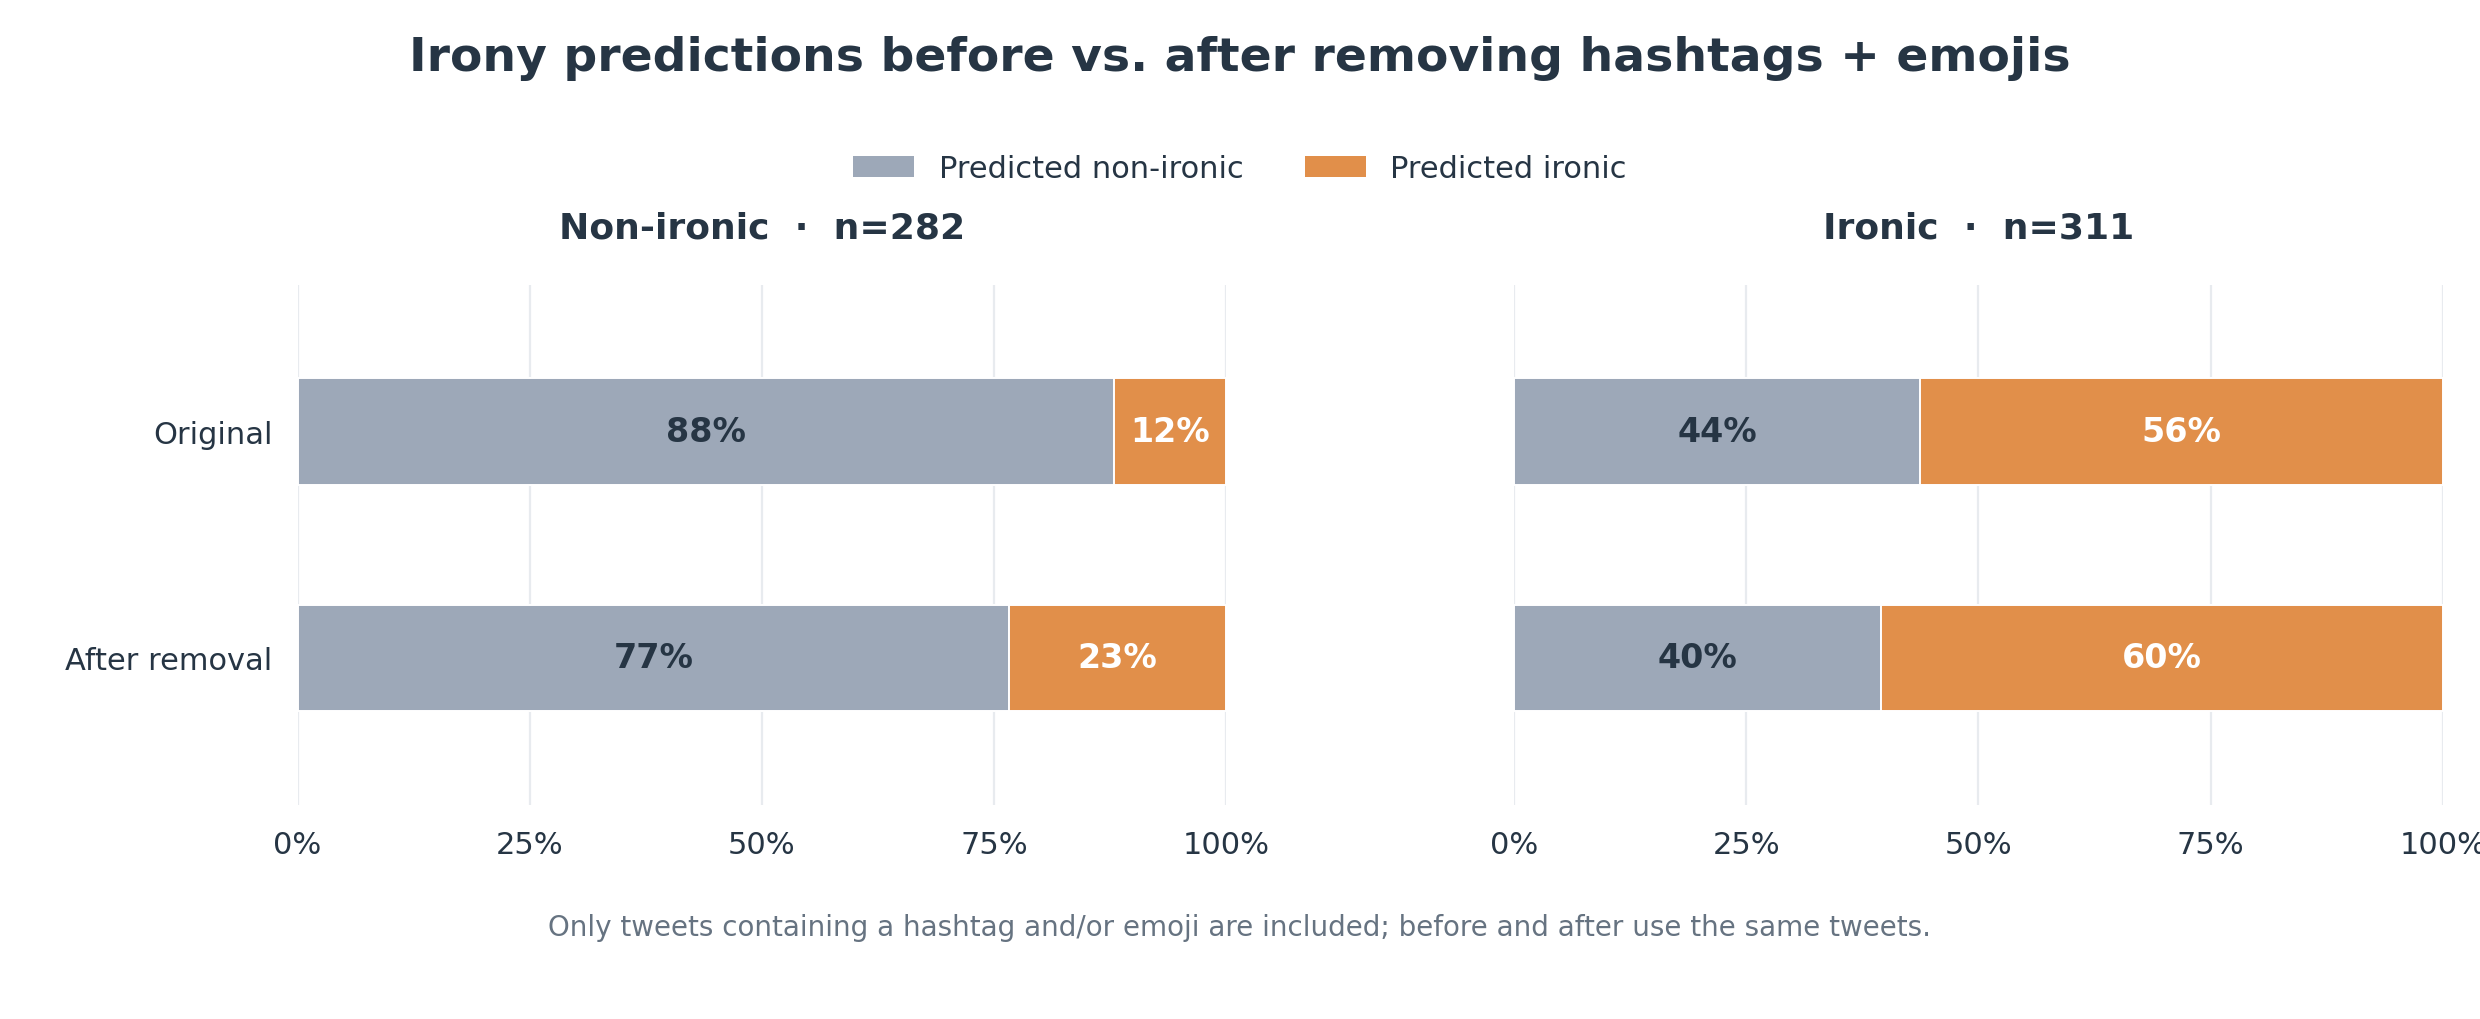

In [12]:
_verify(predictions)
_style()
plot_original_vs_modified(predictions, RESULTS_DIR)
display(Image(filename=str(RESULTS_DIR / "01_original_vs_modified_irony.png")))

### Figure 2 — Prediction-change rates

This chart shows the share of affected tweets whose **predicted label flipped**. Compare the two classes with care: after hashtag removal, 15.4% of affected ironic vs. 13.1% of affected non-ironic tweets flip; the 95% bootstrap interval for their difference includes zero.

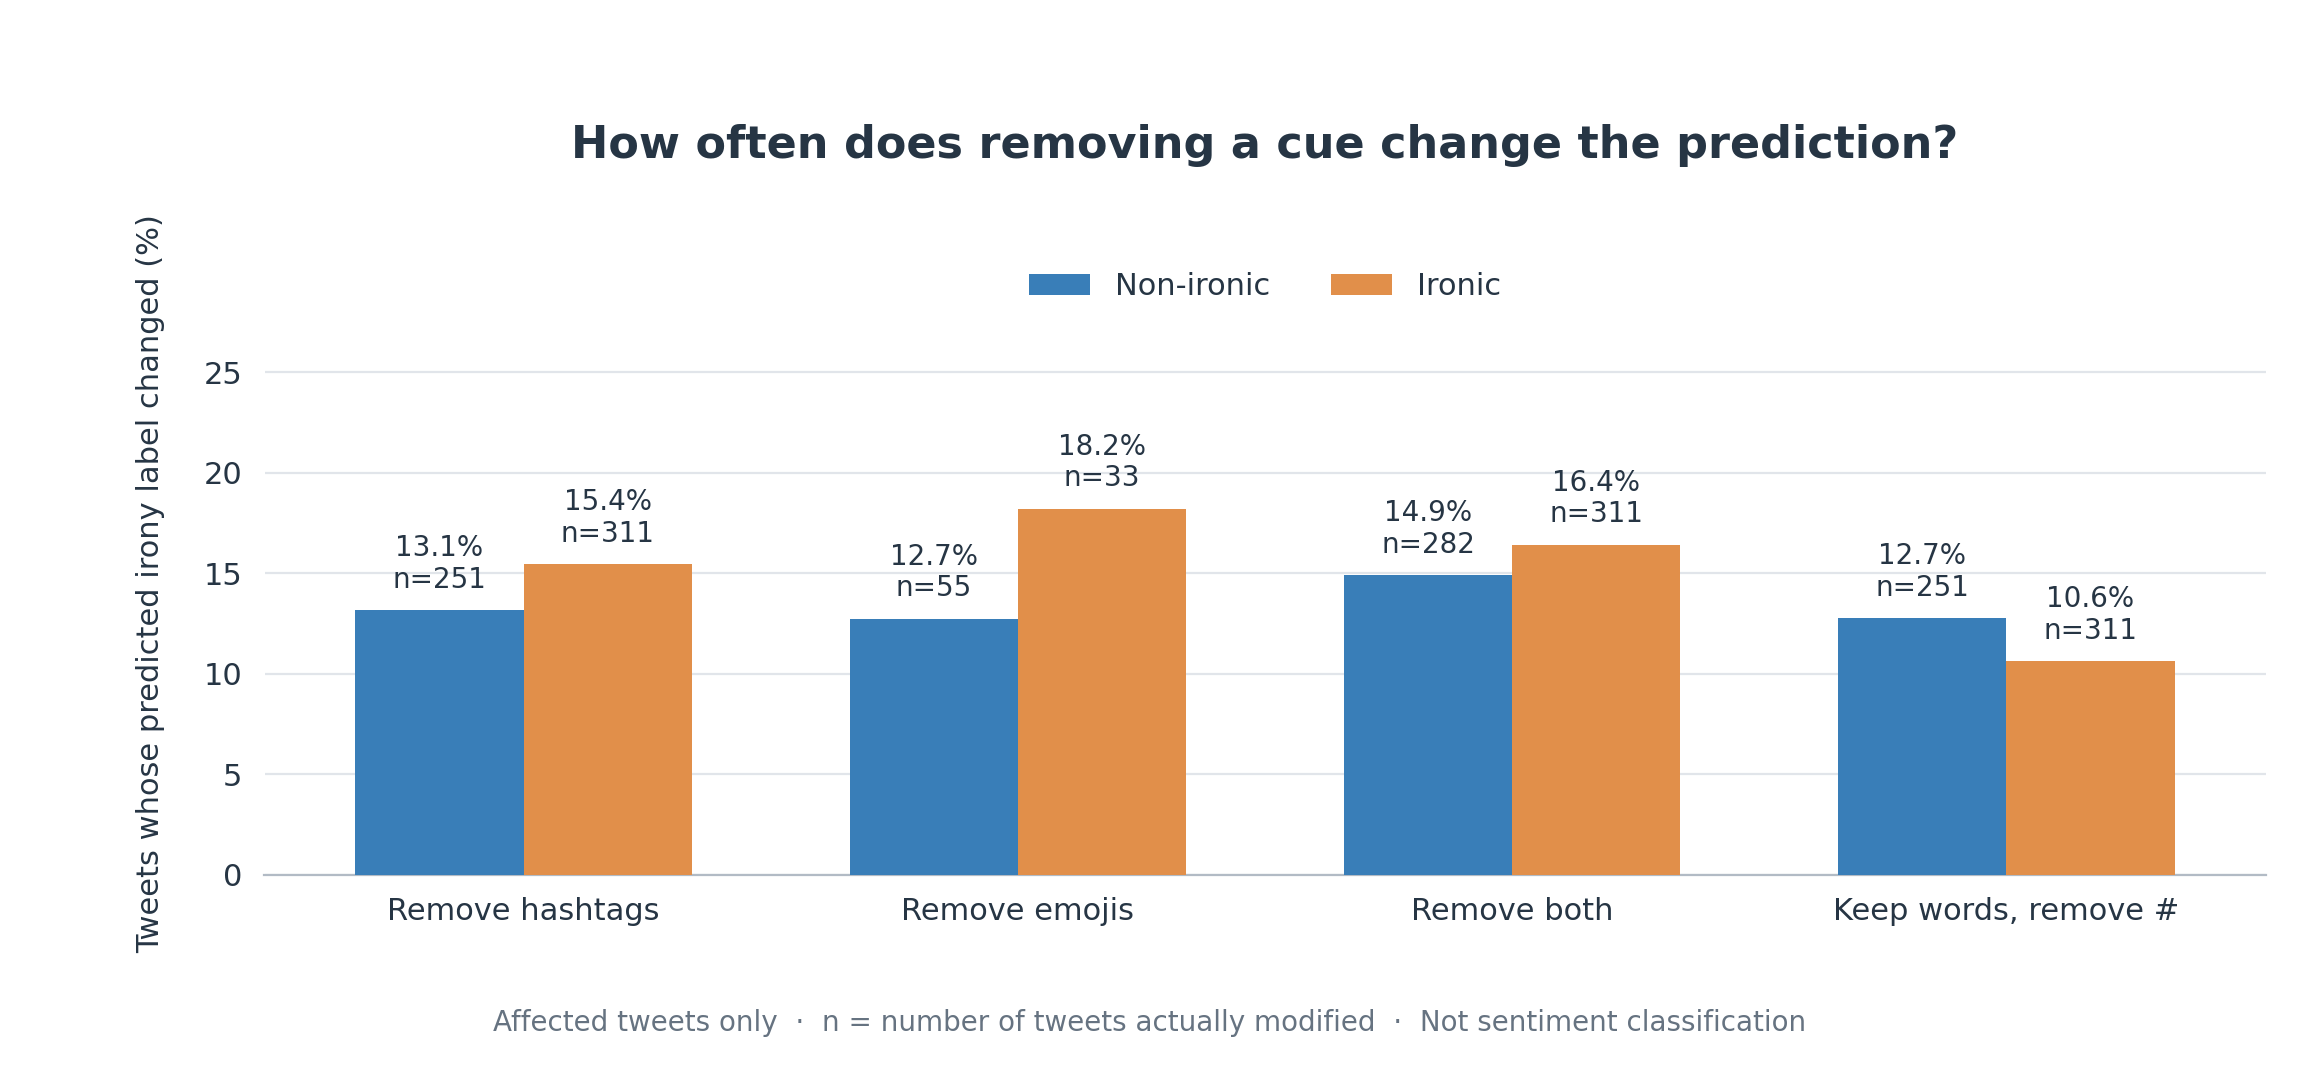

In [13]:
plot_prediction_changes(predictions, RESULTS_DIR)
display(Image(filename=str(RESULTS_DIR / "02_prediction_changes_irony.png")))

### Figure 3 — Probability changes

Individual dots are affected tweets; diamonds are group averages. A prediction can have a substantial change in **P(irony)** without flipping its final label.

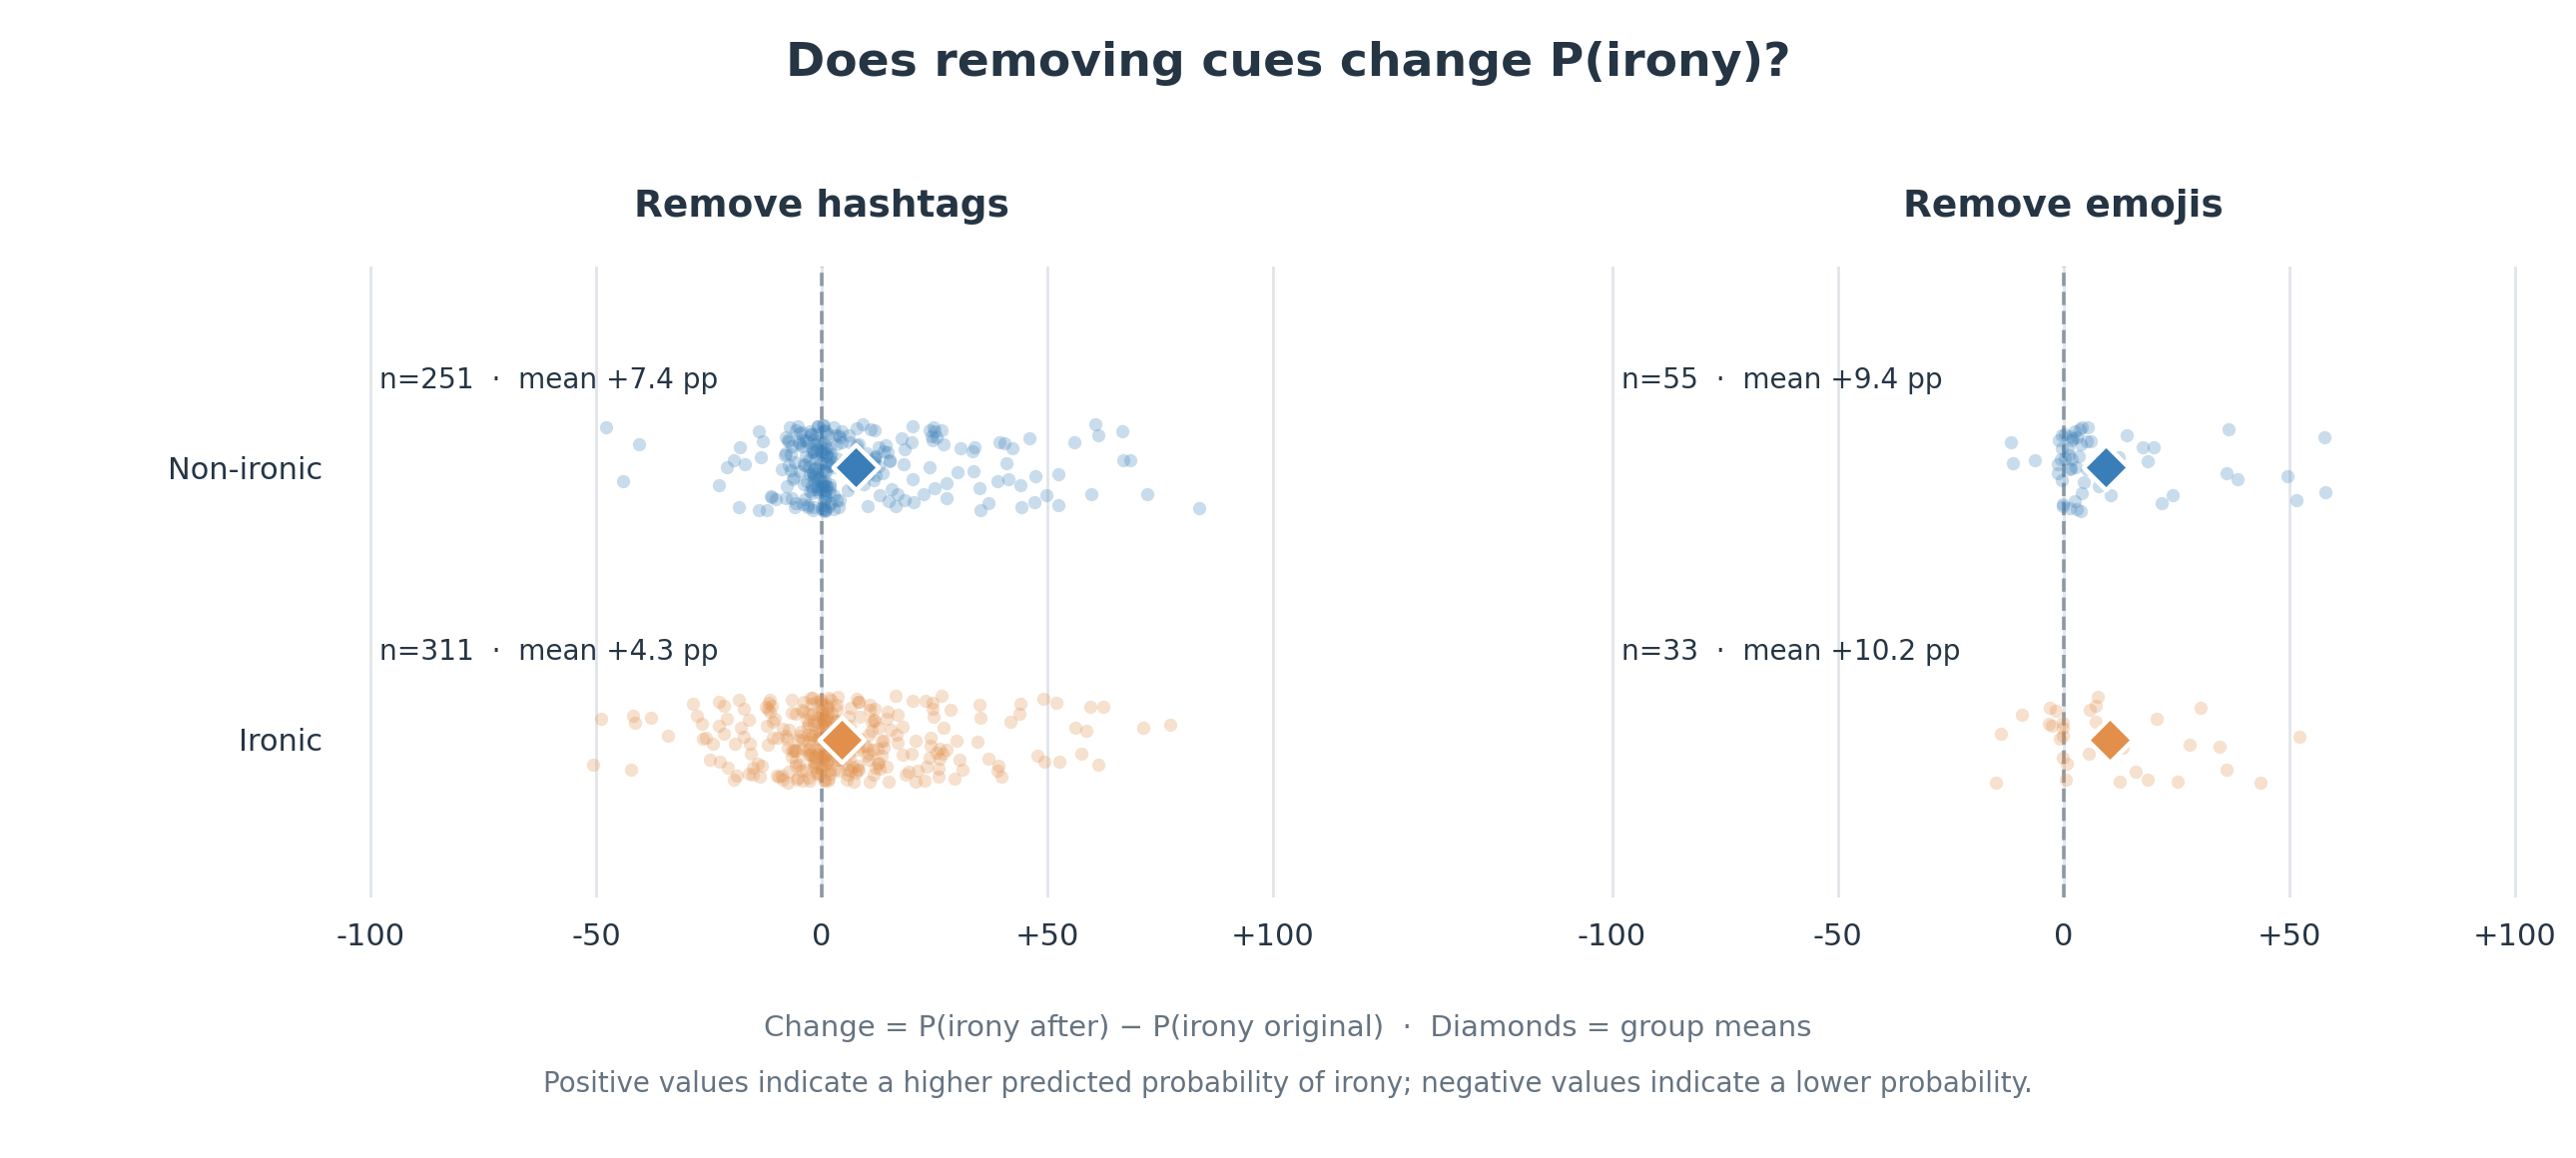

In [14]:
plot_probability_changes(predictions, RESULTS_DIR)
display(Image(filename=str(RESULTS_DIR / "03_probability_changes_irony.png")))

## 6. Statistical checks and limitations

The next two cells summarize the affected-tweet rates and check confidence intervals directly from the prediction data, rather than relying only on descriptions of the plots. The percentages refer to **affected tweets only**.

In [15]:
summary_rows = statistics[statistics.scope.eq("affected_only")].copy()
summary_rows["flip_rate_percent"] = 100 * summary_rows["flip_rate"]
summary_rows["mean_delta_P_irony_pp"] = 100 * summary_rows["mean_delta_p_irony"]
display(summary_rows[["modification", "group", "n", "flip_rate_percent", "mean_delta_P_irony_pp"]]
        .rename(columns={"modification":"Modification", "group":"Ground truth", "n":"Affected tweets",
                         "flip_rate_percent":"Label flips (%)", "mean_delta_P_irony_pp":"Mean ΔP(irony) (pp)"})
        .round(1).reset_index(drop=True))

intervals = bootstrap.copy()
for c in ("flip_rate_difference", "ci95_low", "ci95_high"):
    intervals[c] *= 100
display(intervals[["modification", "n_ironic", "n_non_ironic", "flip_rate_difference", "ci95_low", "ci95_high"]]
        .rename(columns={"modification":"Modification", "n_ironic":"Ironic n", "n_non_ironic":"Non-ironic n",
                         "flip_rate_difference":"Difference (pp)", "ci95_low":"95% lower (pp)", "ci95_high":"95% upper (pp)"})
        .round(1).reset_index(drop=True))

,Modification,Ground truth,Affected tweets,Label flips (%),Mean ΔP(irony) (pp)
0,Remove hashtags,Non-ironic,251,13.1,7.4
1,Remove hashtags,Ironic,311,15.4,4.3
2,Remove emojis,Non-ironic,55,12.7,9.4
3,Remove emojis,Ironic,33,18.2,10.2
4,Remove both,Non-ironic,282,14.9,8.9
5,Remove both,Ironic,311,16.4,5.5
6,"Keep words, remove #",Non-ironic,251,12.7,4.7
7,"Keep words, remove #",Ironic,311,10.6,0.4


,Modification,Ironic n,Non-ironic n,Difference (pp),95% lower (pp),95% upper (pp)
0,Remove hashtags,311,251,2.3,-3.4,8.0
1,Remove emojis,33,55,5.5,-9.7,21.8
2,Remove both,311,282,1.5,-4.3,7.4
3,"Keep words, remove #",311,251,-2.1,-7.5,3.6


**Interpretation limits:**

- Removing hashtags deletes words such as `not` in `#not`, so these tests do **not** isolate punctuation effects.
- The marker-only intervention removes `#` but keeps the word, addressing one important confound.
- Ironic and non-ironic tweets are not content-matched. In the test data all ironic tweets carry at least one `#not`, `#irony` or `#sarcasm` marker, while only a subset of non-ironic tweets do.
- Emoji effects rest on small affected subgroups (33 ironic and 55 non-ironic).
- Bootstrapping provides uncertainty estimates for the observed *difference in flip rates*, not a causal interpretation.

## 7. Three selected tweet examples

These are the three cases discussed in the project's AI interaction log. The before/after text and model probabilities are loaded from **the current prediction data** (not hard-coded sentiment examples). Tweet IDs **231**, **307**, and **622** are included.

In [16]:
ids = [231, 307, 622]
case_df = predictions[predictions.tweet_id.isin(ids)].set_index("tweet_id").loc[ids].reset_index()
for item in case_df.itertuples():
    print("─"*84)
    print(f"TWEET {item.tweet_id} — Ground truth: {item.group}")
    print("ORIGINAL: ", item.text_original)
    print("MODIFIED: ", item.text_no_hashtags)
    print(f"P(irony): {item.original_p_irony:.1%} → {item.no_hashtags_p_irony:.1%}")
    print(f"Prediction: {item.original_prediction} → {item.no_hashtags_prediction}")
    print(f"Correct: {item.original_correct} → {item.no_hashtags_correct}")

────────────────────────────────────────────────────────────────────────────────────
TWEET 231 — Ground truth: Ironic
ORIGINAL:  i just enjoy throwing up #not #hatethis #sick #wanna #go #to #school #for #once #take #me #away
MODIFIED:  i just enjoy throwing up
P(irony): 18.7% → 95.9%
Prediction: non_irony → irony
Correct: False → True
────────────────────────────────────────────────────────────────────────────────────
TWEET 307 — Ground truth: Ironic
ORIGINAL:  That's always the solution..... #not. Doesn't fix anything!
MODIFIED:  That's always the solution..... . Doesn't fix anything!
P(irony): 22.9% → 94.0%
Prediction: non_irony → irony
Correct: False → True
────────────────────────────────────────────────────────────────────────────────────
TWEET 622 — Ground truth: Non-ironic
ORIGINAL:  #forgive #others #not #because they #deserve #forgiveness #you #peace love this from @user #words #wisdom ...
MODIFIED:  they love this from @user ...
P(irony): 14.6% → 98.3%
Prediction: non_irony →

**How to read the examples:** Tweets 231 and 307 are ironic tweets whose predictions change from incorrect to correct after hashtag deletion; tweet 622 is non-ironic and changes from correct to incorrect. These selected cases illustrate different outcomes, but they are not representative estimates or evidence of the model's internal reasoning.

## 8. Conclusions

The **correct irony model** is sensitive to some hashtag and emoji removals, sometimes improving and sometimes worsening its predictions. Removing hashtags changes predicted labels for **15.4%** of affected ironic tweets and **13.1%** of affected non-ironic tweets. This small difference does not establish stronger sensitivity for the ironic group: the 95% bootstrap interval includes zero.

Deleting entire hashtags also deletes words, while irony and non-irony groups contain different kinds of hashtags. The emoji-containing subgroups are small. These limitations matter when interpreting model behavior.

**Submission:** The `.ipynb` alone includes the Python code, inline chart outputs, interpretation, and team AI interaction log. Generated CSV and PNG files are optional artifacts, not notebook dependencies.


---
### Reproducibility

- **Model:** [CardiffNLP Twitter-RoBERTa Irony](https://huggingface.co/cardiffnlp/twitter-roberta-base-irony), unmodified.
- **Test set:** [CardiffNLP TweetEval irony/test](https://github.com/cardiffnlp/tweeteval/tree/main/datasets/irony), 784 tweets, ground-truth labels 0 = non-irony and 1 = irony.
- **Data loading:** Optional local `results_irony/predictions.csv` (or `predictions.csv`) for fast replay; otherwise model inference automatically downloads the official test data and checkpoint. No data or predictions are encoded into source cells.
- **Notebook figures:** Original Python-generated figures with saved notebook outputs; stand-alone PNG export is optional.
- **Dependencies:** NumPy, pandas, Matplotlib; live inference additionally needs PyTorch, Transformers, Emoji, and internet access to download model weights. The notebook installs missing inference packages in live mode.
